
# makemore: part 3

In [147]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
import time
import numpy as np
import random
import torch.nn as nn

device = 'cpu'
if torch.cuda.is_available():
    device = 'cuda'
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
   device = "mps:0"

print(f"Running on {device}")


Running on mps:0


In [148]:

### build the dataset
block_size = 1
T = 128
end_char = '_' 
batch_size = 512

DATA = "words"
DATA = "shakespaere"

if DATA == "words": # read in all the words
    with open("data/names.txt", "r") as f:
        words = f.readlines()
    words = [word.strip() for word in words]
    #random.seed(42)
    random.shuffle(words)
    if end_char in "".join(words): exit(f"the character '{end_char}' is already in the vocabulary")
    text = "_".join(words)
elif DATA == "claire":
    ########### LOAD FROM DATASET
    from datasets import load_dataset
    import re
    import unicodedata

    # Login using e.g. `huggingface-cli login` to access this dataset
    ds = load_dataset("OpenLLM-France/Claire-Dialogue-French-0.1")

    dialogues = [el['text'] for el in ds['train']]

    # Refomating
    to_remove_c = "µ"
    dialogues = [el.replace(to_remove_c, "") for el in dialogues]
    dialogues = [re.sub(r'\[.*?\] ', '', el) for el in dialogues]
    dialogues = [unicodedata.normalize('NFKD', el).encode('ascii', 'ignore').decode('utf-8') for el in dialogues]

    print(dialogues[0][:100])
    print(len(dialogues), "dialogues loaded")

    start_word = 0

    #### SPLITS
    for i in range (1000):
        if sum(len(w) + 1 for w in dialogues[start_word:start_word+i]) > 2000_000:
            words = dialogues[start_word:start_word+i]
            print( i,"cut at", i + start_word, "dialogues with ", sum(len(w) + 1 for w in words), "characters")
            start_word += i
            break
elif DATA == "shakespaere":
    with open("data/tiny_shakespeare.txt", "r") as f:
        text = f.read()

# here are all the unique characters that occur in this text
chars = sorted(list(set(text)))
vocab_size = len(chars)
# create a mapping from characters to integers
stoi = { ch:i for i,ch in enumerate(chars) }
itos = { i:ch for i,ch in enumerate(chars) }
encode = lambda s: [stoi[c] for c in s] # encoder: take a string, output a list of integers
decode = lambda l: ''.join([itos[i] for i in l]) # decoder: take a list of integers, output a string



class DataLoader:
    def __init__(self, data):
        self.data = data.to(device)
        self.reset()
        self.easy_mode = False
        #Xb, targets = Xb.to(device), targets.to(device)

    def reset(self):
        self.batch_reset = True
        self.index = random.randint(0, T)

    def get_batch(self):
        buf = self.data[self.index : self.index+batch_size*T+1]
        x = (buf[:-1]).view(batch_size, T) # inputs
        y = (buf[1:]).view(batch_size, T) # targets

        self.index += batch_size * T
        if self.index + batch_size * T + 1 > len(self.data):
            self.reset()
        return x, y


# Train and test splits
data = torch.tensor(encode(text))#, dtype=torch.long)
n = int(0.9*len(data)) # first 90% will be train, rest val
DLtr = DataLoader(data[:n])
DLte = DataLoader(data[n:])
print(f"vocab size {vocab_size} ,loaded {n} tokens : {n//batch_size} Time learning - {n//(batch_size * T)} batches")

# show first 5 examples
xb, yb = DLtr.get_batch()
print(f"ex : {decode(xb[0][:30].tolist())}")
for i in range(15,20):
    x = xb[:, i:i+block_size]
    y = yb[:, i+block_size - 1]
    #print(x, y)
    for b in range(2):
        print("X", i, ":", decode(x[b].tolist()), '-->', decode([y[b].tolist()]), end = "      \t\t")
    print()

for i in range(100):
    x, y = DLtr.get_batch()
    
    #print("X", i, ":", decode(x[0].tolist()), '-->', decode([y[0].tolist()]))
    assert x.shape == (batch_size,T), x.shape 
    assert y.shape == (batch_size,T), "mlkjqmlkdjf"
    assert (0 <= x).all() and  (x < vocab_size).all()
    assert (0 <= y).all() and (y < vocab_size).all()


DLtr.reset()


vocab size 65 ,loaded 1003854 tokens : 1960 Time learning - 15 batches
ex : en:
Before we proceed any furt
X 15 : r --> o      		X 15 : R --> e      		
X 16 : o --> c      		X 16 : e --> s      		
X 17 : c --> e      		X 17 : s --> o      		
X 18 : e --> e      		X 18 : o --> l      		
X 19 : e --> d      		X 19 : l --> v      		


# MODEL

In [149]:
def myprint(t, name):
    print(f"{name:<10} : {tuple(t.shape)} ")#: {t[:1].tolist()}")


torch.set_default_dtype(torch.float32)


class MyModule(nn.Module):
    debug = False
    def states(self):return []
    def reset_state(self): return "default reset"
    def to(self, device):

        states =  self.states()
        for i in range(len(states)):
            if states[i] is None: continue # Ensure parameter exists
            states[i].data = states[i].data.to(device)  # Update the data in-place
        return super().to(device)

        
    def call(self, fn, *args): 
        return fn(self, *args) if callable(fn) else f"{fn} is not callable"
    

# -----------------------------------------------------------------------------------------------

class Embedding(MyModule): # for each vocab index, look up the corresponding vector in a table
    def __init__(self, num_embeddings, embedding_dim):
        super().__init__()
        self.weight = nn.Parameter(torch.randn((num_embeddings, embedding_dim)))
        self.IX = torch.zeros(32)
        
    def __call__(self, IX): # IX : (Batch, T(Time))
        self.IX = IX
        self.out = self.weight[IX] 
        return self.out # (B, T, C : channel)
    
    def backward(self, delta, x=None):
        IX = self.IX
        flattened_indices = IX.view(-1)  # Shape: (Batch * T)
        flattened_delta = delta.view(-1, delta.shape[-1])  # Shape: (Batch * T, Embedding_dim)
        self.weight.grad.index_add_(0, flattened_indices, flattened_delta)
        return self.weight.grad
    
# PYTORCHIFYING -----------
class Linear(MyModule):
    
    def __init__(self, fan_in, fan_out, bias=True):
        super().__init__()
        self.weight = nn.Parameter(torch.randn((fan_in, fan_out)) * (2/(fan_in+fan_out)) )
        self.bias = nn.Parameter(torch.zeros(fan_out)) if bias else None
    
    def __call__(self, x):
        self.x = x
        self.out = x @ self.weight
        if self.bias is not None:        
            self.out += self.bias
        return self.out
    
    def backward(self, delta, x=None, grad=True): # delta : (batch, T, fan_out)
        if x is None: x = self.x

        if grad:
            if self.bias is not None:
                self.bias.grad += delta.sum(dim=tuple(range(delta.ndim - 1)))

            x_reshaped = x.view(-1, x.shape[-1])  # Shape: (B * T, D)
            delta_reshaped = delta.view(-1, delta.shape[-1])  # Shape: (B * T, C)
            self.weight.grad += x_reshaped.T @ delta_reshaped  # Shape: (fan_in, fan_out)

        x_grad = delta @ self.weight.T # x grad : (batch, fan_in)
        return x_grad

    
# -----------------------------------------------------------------------------------------------
class LayerNorm(MyModule):
    def __init__(self, dim, eps=1e-5):
        super().__init__()
        self.eps = eps # for numerical stability
        self.dim = dim
        self.gamma = nn.Parameter(torch.ones(dim)) # (dim)
        self.beta = nn.Parameter(torch.zeros(dim)) # (dim)

    
    def __call__(self, x):
        self.compute_mms(x)
        self.out = self.gamma * (self.mu * self.sigma_inv) + self.beta
        return self.out
    
    def compute_mms(self, x):
        # calculate the forward pass
        self.xmean = x.mean(dim=-1, keepdim=True)
        self.mu = x - self.xmean
        xvar = x.var(dim=-1, unbiased=False, keepdim=True)
        self.sigma_inv = torch.sqrt(xvar + self.eps)**(-1) # normalize to unit variance
    
    
    def backward(self, delta, x=None, grad=True): # delta : (batch, T ..., dim)
        if x is not None:
            self.compute_mms(x)
        mu, sigma_inv, gamma = self.mu, self.sigma_inv, self.gamma

        if grad:
            self.beta.grad += delta.sum(dim=tuple(range(delta.ndim - 1)))
            self.gamma.grad += (delta * mu * sigma_inv).sum(dim=tuple(range(delta.ndim - 1)))  # sum over batch : (dim)  
        
        # b:batch, h:hidden
        delta = (
            delta*gamma.unsqueeze(0) * sigma_inv
            - 1/self.dim * (torch.einsum('...h,h,...i->...', [delta, gamma, sigma_inv]).unsqueeze(-1) 
                 + mu * torch.einsum('...h,h,...h,...i->...', [delta, gamma, mu, sigma_inv**(3)]).unsqueeze(-1))
        ) 
        return delta # delta : (batch, dim)

  
# -----------------------------------------------------------------------------------------------

class Tanh(MyModule):
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out
    def backward(self, delta, x=None, grad=True):
        if x is not None:
            self.__call__(x)
        return delta * (1 - self.out**2)

# -----------------------------------------------------------------------------------------------

# Module to apply multiple layers in parralel on a split of the input


# -----------------------------------------------------------------------------------------------

class Flatten(MyModule):
    def __init__(self, input_shape, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.input_shape = input_shape

    def __call__(self, x):
        self.out = x.view(x.shape[0], -1)
        return self.out
    def backward(self, delta, x=None):
        return delta.view(self.input_shape)
    

    
# -----------------------------------------------------------------------------------------------

# model class for looping over a layer
# this class is STATEFUL, it keeps track of the hidden state
class Loop(MyModule):
    def __init__(self, input_dim, output_dim, hidden_dim):
        super().__init__()
        layers = nn.ModuleList([ Linear(input_dim + hidden_dim, hidden_dim + output_dim, bias=True), 
                        LayerNorm(hidden_dim + output_dim), Tanh()])
        self.layer = Sequential(layers=layers, save_x=True, input_dim=(input_dim + hidden_dim))

        self.input_dim = input_dim
        self.output_dim = output_dim
        self.hidden_dim = hidden_dim

        self.initial_h = nn.Parameter(torch.randn(1, hidden_dim))  # initialize hidden state to zeros

        self.no_direct_input = False
        self.no_loop = False
        self.device = None
        self.reset_state()

    def reset_state(self):
        #backward state
        self.dgrad = torch.zeros(batch_size, self.hidden_dim, device=self.device)
        # initialize hidden state : (different hidden state for each example in the batch)
        self.h = self.initial_h.expand(batch_size, -1) # (batch, hidden_dim)



    def __call__(self, x): # x : (batch, T, input_dim) and h : (1, hidden_dim)
        # LOOP over all the times
        y = torch.zeros(batch_size, T, self.output_dim, device=self.device)
        for t in range(T): # loop over all the times
            xt = x[:,t]
            yt, self.h = self.forward_T(xt, self.h, t)
            if self.no_loop: self.h = torch.zeros_like(self.h)
            y[:,t] = yt
        return y

    def forward_T(self, xt, h, t): # x : (batch, input_dim) and h : (1, hidden_dim)
        # CONCATENATE input and previous hidden state
        if self.no_direct_input:
            inp = torch.cat([torch.zeros_like(xt), h], dim=-1) # (batch, input_dim + hidden_dim)
            out = self.layer(inp) # (batch, output_dim + hidden_dim)
            y, _ = out.split([self.output_dim, self.hidden_dim], dim=-1) # (batch, hidden_dim), (batch, output_dim)
            
            inp = torch.cat([xt, h], dim=-1) # (batch, input_dim + hidden_dim)
            out = self.layer(inp) # (batch, output_dim + hidden_dim)
            _, h = out.split([self.output_dim, self.hidden_dim], dim=-1) # (batch, hidden_dim), (batch, output_dim)
        else:
            inp = torch.cat([xt, h], dim=-1) # (batch, input_dim + hidden_dim)
            out = self.layer(inp) # (batch, output_dim + hidden_dim)
            y, h = out.split([self.output_dim, self.hidden_dim], dim=-1) # (batch, hidden_dim), (batch, output_dim)
        return y, h
    
    def states(self):
        return [self.h, self.dgrad]
    
    def call(self, fn, *args): # call the fn function of all layers
        return [super().call(fn, *args)] + self.layer.call(fn, *args)

    def backward(self, delta, x=None): # (B, T, out dim)
        T = delta.shape[1]
        delta_out = torch.zeros(batch_size, T, self.input_dim, device=self.device)
        for t in range(T-1, -1, -1):
            delta_t = delta[:,t]
            delta_out_t = self.backward_T(delta_t, t)
            delta_out[:,t] = delta_out_t
        return delta_out

    def backward_T(self, delta_t, t):
        if self.no_direct_input:
            dldOut = torch.cat([torch.zeros_like(delta_t), self.dgrad], dim=-1)
            dldIn = self.layer.backward(dldOut, grad=False)
            delta_out, _ = dldIn.split([self.input_dim, self.hidden_dim], dim=-1)

            dldOut = torch.cat([delta_t, self.dgrad], dim=-1)
            dldIn = self.layer.backward(dldOut)
            _, self.dgrad = dldIn.split([self.input_dim, self.hidden_dim], dim=-1)
        else:
            dldOut = torch.cat([delta_t, self.dgrad], dim=-1)
            dldIn = self.layer.backward(dldOut)
            delta_out, self.dgrad = dldIn.split([self.input_dim, self.hidden_dim], dim=-1)
        if self.no_loop: self.dgrad = torch.zeros_like(self.dgrad)

        if t == 0:
            self.initial_h.grad += self.dgrad.sum(dim=0)
        return delta_out


# -----------------------------------------------------------------------------------------------

class Sequential(MyModule):
    def __init__(self, layers, save_x=False, input_dim=None, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.layers = nn.ModuleList(layers)
        self.save_x = save_x
        self.input_dim = input_dim
        self.device = None

        self.update_BT_size()
    
    def reset_state(self):
        if self.save_x:
            self.t = 0

    def update_BT_size(self):
        if not self.save_x: return
        self.t = 0
        self.saved_x = []
        ## INPUT : (B,T,inp) -> (B,inp) -> (B, inp + hidden) 
        xt = torch.zeros(batch_size, self.input_dim, device=self.device)
        print(self.device, xt.device)
        for l in self.layers:
            self.saved_x.append(torch.zeros(xt.shape[0], T, *xt.shape[1:], device=self.device))
            xt = l(xt)
    
    def __call__(self, x):
        for i, layer in enumerate(self.layers):
            if self.save_x and self.training:
                self.saved_x[i][:,self.t] = x
            x = layer(x)
        if self.save_x and self.training:
            self.t += 1
        return x
    
    
    def call(self, fn, *args, on_myself=True):  # call the fn function of all layers
        out = [l.call(fn, *args) for l in self.layers]
        if on_myself: out = out + [super().call(fn, *args)]
        return out
    
    def backward(self, delta, x = None, *args): 
        if self.save_x:
            self.t -= 1
            assert self.t >= 0, "t is negative"
        for i, layer in reversed(list(enumerate(self.layers))):
            #print(delta.device, ' brefore' , layer.__class__.__name__ )
            if self.save_x:
                x = self.saved_x[i][:,self.t]
            delta = layer.backward(delta, x=x, *args)
        return delta
    

  
# -----------------------------------------------------------------------------------------------
        
# class to wrap all the layers modules
class Model(Sequential):
    def __init__(self, layers):
        super().__init__(layers)
    
    def self_call(self, fn_name, *args):
        def function(x):
            if not hasattr(x, fn_name):
                return f"{x.__class__.__name__} don't have '{fn_name}'"
            method = getattr(x, fn_name)
            if not callable(method):
                return f"{fn_name} not callable on {x.__class__.__name__}"
            return method(*args), f"{fn_name} called on {x.__class__.__name__}"
            
        return self.call(function, on_myself=False)
    
    def reset_state(self):
        return self.self_call("reset_state")

    def set_var(self, var_name, value):
        return self.call(lambda x: value if setattr(x, var_name, value) is None else "not none")# if hasattr(x, var_name) else f"{var_name} is not an attribute")
        
    




In [150]:

n_embd = 40 # the dimensionality of the character embedding vectors
n_hidden = 256 # the number of neurons in the hidden layer of the MLP
n_out_hidden = n_embd


total_steps, train_index, train_time = 0, 0, 0
lossi = [] # store loss values

CMP = False
torch.set_grad_enabled(CMP)
torch.manual_seed(42)

LOOP = True

if LOOP:
    model = Model([                # (B, T)
        Embedding(vocab_size, n_embd),  # (B, T, C)
        Loop(input_dim=n_embd, output_dim=n_out_hidden, hidden_dim=n_hidden),  
        # loop of T : (B, t  C) -> (B, t, C_h)
        Linear(n_out_hidden, vocab_size) # (B, T, Vocab size)
    ])
else:
    model = Model([
        Embedding(vocab_size, n_embd), 
        Linear(n_embd , n_hidden, bias=True), LayerNorm(n_hidden), Tanh(),  
        Linear(n_hidden, vocab_size)
    ])
# with torch.no_grad():
#     last layer: make less confident
#     model.layers[-1].weight *= 0.1
#     model.layers[-1].bias *= 0.1
#   all other layers: apply gain
#   for layer in model.layers[:-1]:
#     if isinstance(layer, Linear):
#       layer.weight *= 0.5 #* 5/3

model.set_var("device", device)
model = model.to(device)

if CMP:
    for p in model.parameters():
        p.requires_grad = True

print(f"Total parameters : {sum(p.nelement() for p in model.parameters())}")
#print(model)
for name, l in model.named_modules():
    print(f"{l.__class__.__name__:<30} : {name:<30} :   size : {sum(p.nelement() for p in l.parameters())} ({l.device if hasattr(l, 'device') else 'no device'})")
for name, p in model.named_parameters():
    print(f"{name:<30} :  {str(tuple(p.shape)):<20}  size : {p.nelement():<10}  ({p.device})")


def backward_cross_entropy(_y, _Yb): # cross entropy loss backward pass
    dy = F.softmax(_y, dim=-1)
    dy[torch.arange(_y.size(0)), _Yb] -= 1
    dy /= batch_size
    return dy




None cpu
Total parameters : 94025
Model                          :                                :   size : 94025 (mps:0)
ModuleList                     : layers                         :   size : 94025 (no device)
Embedding                      : layers.0                       :   size : 2600 (mps:0)
Loop                           : layers.1                       :   size : 88760 (mps:0)
Sequential                     : layers.1.layer                 :   size : 88504 (mps:0)
ModuleList                     : layers.1.layer.layers          :   size : 88504 (no device)
Linear                         : layers.1.layer.layers.0        :   size : 87912 (mps:0)
LayerNorm                      : layers.1.layer.layers.1        :   size : 592 (mps:0)
Tanh                           : layers.1.layer.layers.2        :   size : 0 (mps:0)
Linear                         : layers.2                       :   size : 2665 (mps:0)
layers.0.weight                :  (65, 40)              size : 2600        (

In [151]:
# same optimization as last time
steps = 2_0

batch_size = 512# 256
T = 128


model.train()
model.set_var("no_direct_input", False)
model.set_var("no_loop", False)
model.self_call("update_BT_size")

for p in model.parameters():
    p.grad = torch.zeros_like(p)


total_steps = len(lossi)
steps = steps - total_steps % steps 
total_steps += steps
start_time = time.time()
print(f"Starting training on {device} for {steps} steps")

for i in range(steps):
    # minibatch construct : sample a random subset of the data
    Xb, targets = DLtr.get_batch() # (B, T)
    # if DLtr.batch_reset:
    #     DLtr.batch_reset = False
    model.reset_state()
    
    # forward pass
    y = model(Xb) # y : (B, T, Vocab size)
    
    targets = targets.view(-1) # (B * T)
    y = y.view(-1, vocab_size) # (B * T, vacab)vocab_size
    loss = F.cross_entropy(y, targets) # y needs to be (B * T, C)


    ############# backward pass ################
    # zero all the gradients in the model
    for p in model.parameters():
        p.grad.zero_()

    dy = backward_cross_entropy(y, targets)
    dy = dy.view(batch_size, T, -1) # (B, T, C)
    delta = model.backward(dy)

    if CMP: 
        # zero all the gradients in the model
        for p in model.parameters():
            p.grad = None
        y.retain_grad() 
        loss.backward() # backpropagate the error
        cmp("dy", dy, y.grad, only_errors=True)

    ##################################################

    # update
    lr = 0.0001 if train_index < 1800 else 0.00002 # step learning rate decay    
    
    for name, p in model.named_parameters():
        p.data += -lr * p.grad
        #if CMP: cmp(name, p.grad, g, only_errors=True)
        
    

    # track stats
    lossi.append(loss.log10().item())
    if i % (steps//10) == 0: # print every once in a while
        dt = time.time() - start_time
        start_time = time.time()
        train_time += dt
        processed_tokens = (steps//10) * batch_size * T
        average_loss = sum(lossi[-(steps//10):])/len(lossi[-(steps//10):])
        print(f'{train_index:7d}/{total_steps:7d}:  {average_loss:.4f} - {10**average_loss:.4f}  ({train_time:.0f}s : +{dt:.0f}s)  {processed_tokens / (dt*1e3):.0f} k tok/s')
    
    train_index += 1
print(f"Training time: {train_time:.0f} seconds")





mps:0 mps:0
Starting training on mps:0 for 20 steps
      0/     20:  0.6210 - 4.1783  (0s : +0s)  356 k tok/s
      2/     20:  0.6148 - 4.1193  (1s : +1s)  207 k tok/s
      4/     20:  0.6092 - 4.0666  (2s : +1s)  209 k tok/s
      6/     20:  0.6057 - 4.0334  (2s : +1s)  209 k tok/s
      8/     20:  0.6024 - 4.0032  (3s : +1s)  210 k tok/s
     10/     20:  0.5995 - 3.9761  (4s : +1s)  203 k tok/s
     12/     20:  0.5959 - 3.9440  (4s : +1s)  214 k tok/s
     14/     20:  0.5936 - 3.9227  (5s : +1s)  209 k tok/s
     16/     20:  0.5904 - 3.8938  (5s : +1s)  211 k tok/s
     18/     20:  0.5883 - 3.8751  (6s : +1s)  212 k tok/s
Training time: 6 seconds


mean tensor(0.0027, device='mps:0')
100.0 % non zero weights
20% threshold: 0.0013098142808303237


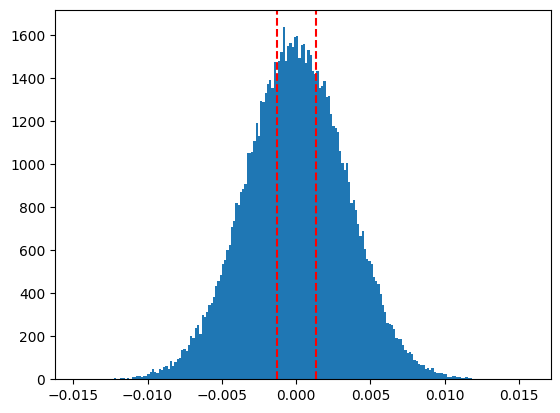

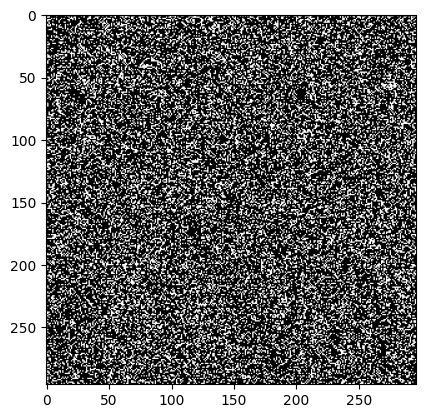

In [152]:



def show(layer):
    if layer.__class__.__name__ == "Loop":
        #loop_w[:n_embd * block_size, :n_out_hidden] = 0
        #plt.imshow(loop_w)
        loop_w = layer.layer.layers[0].weight
        print("mean", loop_w.abs().mean())
        print(f"{loop_w.count_nonzero()/ loop_w.nelement() *100} % non zero weights")
        
        
        # calculate the 20% threshold
        threshold = np.percentile(loop_w.abs().cpu().numpy(), 30)
        print(f"20% threshold: {threshold}")

        plt.hist(loop_w.flatten().cpu().numpy(), bins=200)
        plt.axvline(x=-threshold, color='r', linestyle='--')
        plt.axvline(x=threshold, color='r', linestyle='--')
        plt.show()


        # represent 20 % that are the closest to 0
        plt.imshow(torch.abs(loop_w).cpu().numpy() > threshold, cmap= 'binary')
        plt.show()

model.call(show);



# 20 steps, 6s (Batch: 512, block: 1, lr: 0.0001, hidden: 256) : 3.8457669417063394
# train loss : 3.8389   	 acc 15.3% 	 prob 2.4%     (log:0.5842024776011842)
# test  loss : 3.8458  	 acc 15.2% 	 prob 2.4%
Overfitting : 0.006905142466226977


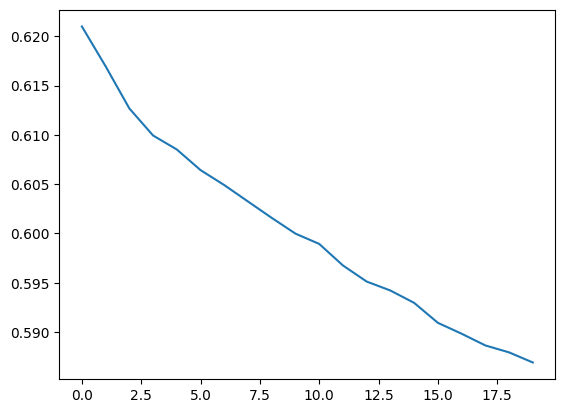

In [153]:


model.eval()

#  Evaluate the model
@torch.no_grad()  # Disable gradient tracking
def split_loss_and_accuracy(DL, n_iteration=30):
    avg_loss = 0
    correct_predictions = 0
    total_predictions = 0
    avg_correct_prob = 0
    
    for i in range(n_iteration):
        # Get the input and target sequences
        x, y = DL.get_batch()  # Fetch data batch
        model.reset_state()

        # Forward pass through the model
        x = model(x)  # Output logits
        x = x.view(-1, vocab_size)  # Reshape logits for loss computation
        y = y.view(-1)  # Flatten targets

        # Compute loss
        avg_loss += F.cross_entropy(x, y, reduction='mean').item()

        # Compute accuracy
        predictions = torch.argmax(x, dim=1)  # Predicted class indices
        correct_predictions += (predictions == y).sum().item()  # Count correct predictions
        total_predictions += y.size(0)  # Count total predictions
        
        proba = F.softmax(x, dim=1)
        correct_probs = proba[torch.arange(y.size(0)), y]  # Correct class probabilities
        avg_correct_prob += correct_probs.mean().item()

    avg_loss /= n_iteration  # Average the loss over iterations
    accuracy = correct_predictions / total_predictions  # Compute accuracy
    avg_correct_prob /= n_iteration
    return avg_loss, accuracy, avg_correct_prob

trl, tracc, tr_prob = split_loss_and_accuracy(DLtr)
test, teacc, te_prob = split_loss_and_accuracy(DLte)

print(f"# {total_steps} steps, {train_time:.0f}s (Batch: {batch_size}, block: {block_size}, lr: {lr}, hidden: {n_hidden}) : {test}")
print(f"# train loss : {trl:.4f}   \t acc {tracc * 100:.1f}% \t prob {tr_prob * 100:.1f}%     (log:{np.log10(trl)})")
print(f"# test  loss : {test:0.4f}  \t acc {teacc * 100:.1f}% \t prob {te_prob * 100:.1f}%")


print(f"Overfitting : {test - trl}")
if test - trl > 0.1:
    print("\033[91mModel is overfitting\033[0m")

spliter = 10**int(np.log10(len(lossi))-2)

plt.plot(torch.tensor(lossi).view(-1, spliter).mean(1));

# 1 letter

# LOOP  
# # 13000 steps, 708s (Batch: 32, block: 1, lr: 0.01, hidden: 64) : 2.0660481452941895
# train loss : 2.0372254848480225      (log:0.30903910038242466)  
#  test  loss : 2.0660
# 2000 steps, 420s (Batch: 32, block: 1, lr: 0.001, hidden: 256) : 2.0285587986310323
#  train loss : 1.9258   	 acc 45.7% 	 prob 29.6%     (log:0.2846129310450921)
# test  loss : 2.0286  	 acc 42.0% 	 prob 28.2%
## ON shakespaere
# 5700 steps, 972s (Batch: 64, block: 1, lr: 1e-05, hidden: 256) : 1.9928557395935058
# train loss : 1.8798   	 acc 47.4% 	 prob 30.6%     (log:0.27412079568294734)
# test  loss : 1.9929  	 acc 43.3% 	 prob 28.8%




In [ ]:
# sample from the model


model.eval()
model.reset_state()
g = torch.Generator(device=device).manual_seed(2147483647 + 10)
T = 1

def generate_from(model, x, max_tokens=1000):
    # x : (B,T)
    model.call(lambda x: x.reset_state() if hasattr(x, "reset_state") else "ok")

    for i in range(max_tokens):
        inp = x[:,i:i+1]
        y = model(inp).view(-1, vocab_size)
        # print(y.shape)
        if i+1 >= x.shape[1]:
            probs = F.softmax(y, dim=1)
            ix = torch.multinomial(probs, num_samples=1, generator=g)
            x = torch.cat([x, ix], dim = 1)
    return x

x = DLte.get_batch()[0][:, 0:1]
#x = torch.asarray([encode("MENENIUS:\nThe senators of Rome are this good belly,") for _ in range(batch_size)]).to(device)

out = generate_from(model, x, max_tokens=10)

for txt in out[:1]:
    txt = txt.tolist()
    print( f"{len(txt)} tokens :", decode(txt)) #.replace(end_char, " "))
    

IndexError: index 1 is out of bounds for dimension 1 with size 1

In [ ]:

    
b, h = 2, 3
ln = LayerNorm(h)
#ln = torch.nn.LayerNorm(h)
#torch.manual_seed(19)
x = torch.randn(b, h) * 10+ 100
y = torch.randn(b, h)

myprint(x, "x")
myprint(y, "y")

for p in ln.parameters() + [x]:
    p.requires_grad = True
    p.grad = torch.zeros_like(p)

pred = ln(x)
delta = (pred - y)#.sum()
loss = delta.sum()

#loss.backward()

print("loss", loss)

dlddelta = torch.ones_like(pred)
out_delta = ln.backward(dlddelta)

def cmp(s, a, b, only_errors=False):
    app = torch.allclose(a, b, atol=1e-7)
    if only_errors and app: return
    ex = torch.all(a == b).item()
    maxdiff = (a - b).abs().max().item()
    app_color = '\033[92m' if app else '\033[91m'
    exact_color = '\033[92m' if ex else '\033[91m'
    print(f'{s:15s} | {exact_color}exact: {str(ex):5s} {app_color}| approximate: {str(app):5s} | maxdiff: {maxdiff}\033[0m')
    if (a == torch.zeros_like(a)).all() or (b == torch.zeros_like(b)).all():
        print(f"WARNING : ZEROS : a {a.tolist()} and b {b.tolist()}")

for p, g in zip(ln.parameters() + [x], ln.gradients() + [out_delta]):
    cmp("layernorm param", p.grad, g)


x          : (2, 3) 
y          : (2, 3) 


TypeError: unsupported operand type(s) for +: 'generator' and 'list'